# k-nearest neighbors regression applied to bone mineral density

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from ipywidgets import interact, IntSlider

Bone mineral density data, from Hastie, Tibshirani & Friedman, The Elements of Statistical Learning (section 5.4). The response `spnbmd` is the relative change in spinal bone mineral density of adolescents between two consecutive visits, and the covariate is the age (mean of the two visits). The growth of the bones is fastest around puberty, earlier for females than for males.

The k-nearest neighbors regression estimates the mean of the response at a point with the average of the responses of its $k$ closest observations.

In [2]:
dat_original = pd.read_csv('bones_mineral_density.csv')
dat = dat_original[['age', 'gender', 'spnbmd']]

dat.groupby('gender').describe().round(3).T

gender         female     male
age    count  259.000  226.000
       mean    16.106   16.083
       std      4.196    3.948
       min      9.400    9.600
       25%     12.725   12.712
       50%     15.350   15.625
       75%     19.025   19.238
       max     25.550   25.200
spnbmd count  259.000  226.000
       mean     0.039    0.040
       std      0.051    0.049
       min     -0.043   -0.064
       25%      0.004    0.008
       50%      0.022    0.028
       75%      0.065    0.061
       max      0.220    0.211

In [3]:
genders = ['female', 'male']
gender_colors = {'female': '#0072B2', 'male': '#E69F00'}

x = {}
Y = {}
for gender in genders:
    dat_gender = dat[dat['gender'] == gender].sort_values('age')
    x[gender] = dat_gender[['age']].to_numpy()
    Y[gender] = dat_gender['spnbmd'].to_numpy()

x_grid = np.linspace(9, 26, 400)[:, None]

In [4]:
def plot_data(ax, gender_list=genders, alpha=0.8):
    for gender in gender_list:
        ax.plot(x[gender][:, 0], Y[gender], 'o', color=gender_colors[gender], markersize=5, markeredgecolor='white',
                markeredgewidth=0.4, alpha=alpha, label=f'Observed data, {gender}')
    ax.axhline(0, color='#555555', lw=1)
    ax.set_xlabel('Age (years)')
    ax.set_ylabel('Relative change in spinal bone mineral density')
    ax.grid(True, alpha=0.25)

def plot_fit(ax, predictions, title, legend=True):
    plot_data(ax, alpha=0.45)
    for gender in genders:
        ax.plot(x_grid[:, 0], predictions[gender], color=gender_colors[gender], lw=2.5, label=f'kNN fit, {gender}')
    ax.set_title(title)
    if legend:
        ax.legend(loc='upper right', frameon=False)

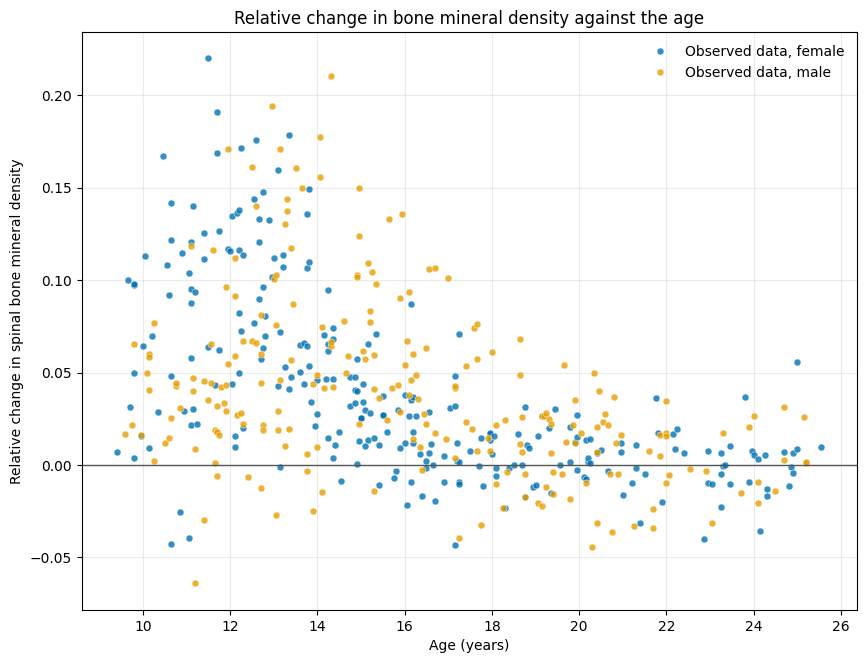

In [5]:
fig, ax = plt.subplots(figsize=(10, 7.5))
plot_data(ax)
ax.set_title('Relative change in bone mineral density against the age')
ax.legend(loc='upper right', frameon=False)

## One neighbor

With $k = 1$ the fit at each age is the response of the closest observation: it passes through the data and is as noisy as they are.

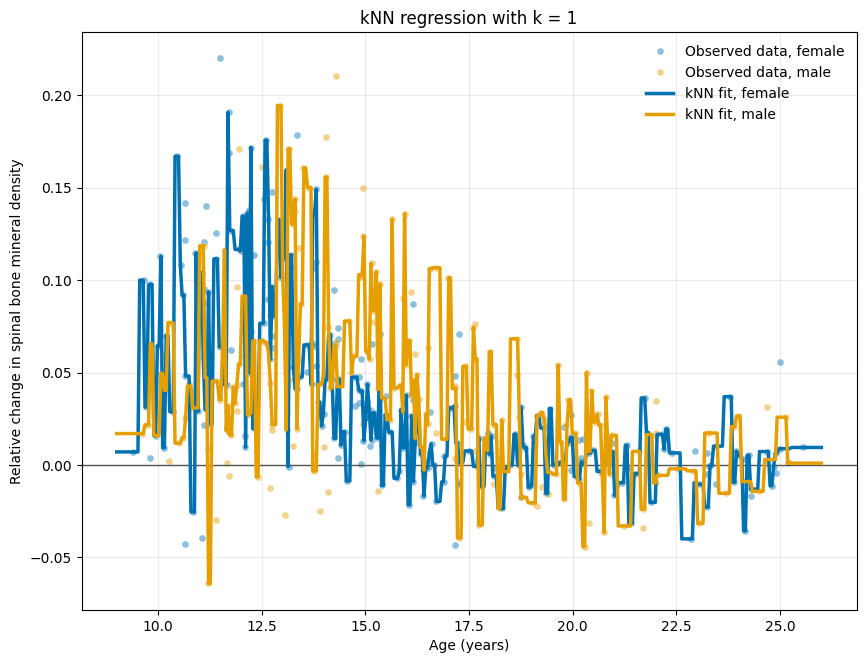

In [6]:
predict_1 = {}
for gender in genders:
    knn_1 = KNeighborsRegressor(n_neighbors=1)
    knn_1.fit(x[gender], Y[gender])
    predict_1[gender] = knn_1.predict(x_grid)

fig, ax = plt.subplots(figsize=(10, 7.5))
plot_fit(ax, predict_1, 'kNN regression with k = 1')

## How it works

For one target age: the $k$ nearest observations (ringed) and their average, which is the fit at that age.

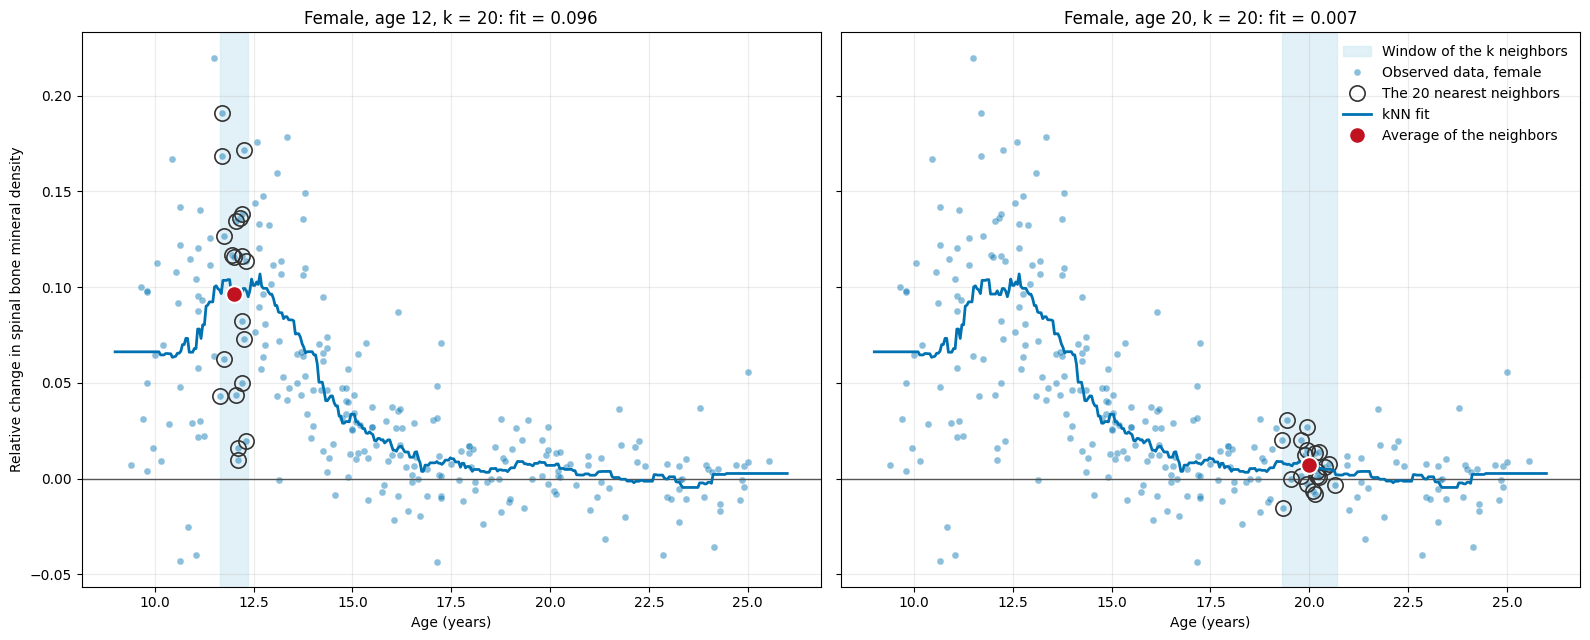

In [7]:
def plot_neighbors(ax, gender, age0, k):
    knn = KNeighborsRegressor(n_neighbors=k).fit(x[gender], Y[gender])
    distances, idx = knn.kneighbors([[age0]])
    idx = idx[0]
    fit0 = knn.predict([[age0]])[0]

    ax.axvspan(age0-distances.max(), age0+distances.max(), color='#cfe8f3', alpha=0.6, label='Window of the k neighbors')
    plot_data(ax, [gender], alpha=0.45)
    ax.plot(x[gender][idx, 0], Y[gender][idx], 'o', markersize=11, markerfacecolor='none', markeredgecolor='#333333',
            markeredgewidth=1.2, label=f'The {k} nearest neighbors')
    ax.plot(x_grid[:, 0], knn.predict(x_grid), color=gender_colors[gender], lw=2, label='kNN fit')
    ax.plot(age0, fit0, 'o', color='#c1121f', markersize=12, markeredgecolor='white', markeredgewidth=1.5,
            label='Average of the neighbors', zorder=5)
    ax.set_title(f'{gender.capitalize()}, age {age0}, k = {k}: fit = {fit0:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True)
plot_neighbors(axes[0], 'female', 12, 20)
plot_neighbors(axes[1], 'female', 20, 20)
axes[1].set_ylabel('')
axes[1].legend(loc='upper right', frameon=False)
plt.tight_layout()

## Choosing k by cross-validation

We choose $k$ between 1 and 30 with 5-fold cross-validation; the score is the coefficient of determination $R^2$ in the observations left out. The data are sorted by age, so we shuffle them before making the folds: otherwise each fold would be a block of consecutive ages, and the model would be evaluated extrapolating to ages it has not seen.

In [8]:
k_range = range(1, 31)
cv = KFold(n_splits=5, shuffle=True, random_state=111)

k_scores = {}
k_star = {}
for gender in genders:
    # use iteration to calculate different k in models, then return the average score based on the cross validation
    k_scores[gender] = []
    for k in k_range:
        knn = KNeighborsRegressor(n_neighbors=k)
        scores = cross_val_score(knn, x[gender], Y[gender], cv=cv)
        k_scores[gender].append(scores.mean())
    k_star[gender] = int(np.argmax(k_scores[gender]))+1

print('Best k:', k_star)

Best k: {'female': 21, 'male': 27}


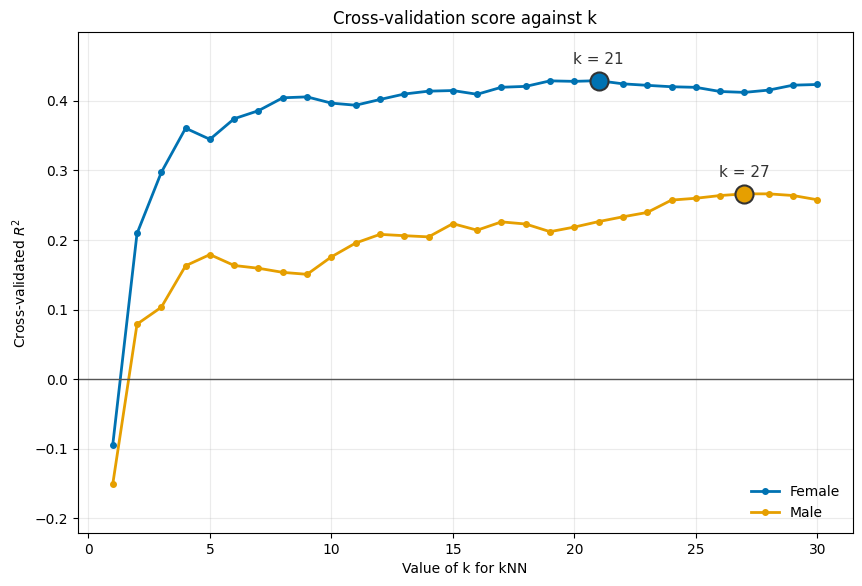

In [9]:
fig, ax = plt.subplots(figsize=(10, 6.5))
for gender in genders:
    ax.plot(k_range, k_scores[gender], 'o-', color=gender_colors[gender], lw=2, markersize=4, label=gender.capitalize())
    ax.plot(k_star[gender], max(k_scores[gender]), 'o', color=gender_colors[gender], markersize=13,
            markeredgecolor='#333333', markeredgewidth=1.5)
    ax.annotate(f'k = {k_star[gender]}', (k_star[gender], max(k_scores[gender])), xytext=(0, 12),
                textcoords='offset points', ha='center', fontsize=11, color='#333333')
ax.axhline(0, color='#555555', lw=1)
ax.set_xlabel('Value of k for kNN')
ax.set_ylabel('Cross-validated $R^2$')
ax.margins(y=0.12)
ax.set_title('Cross-validation score against k')
ax.legend(loc='lower right', frameon=False)
ax.grid(True, alpha=0.25)

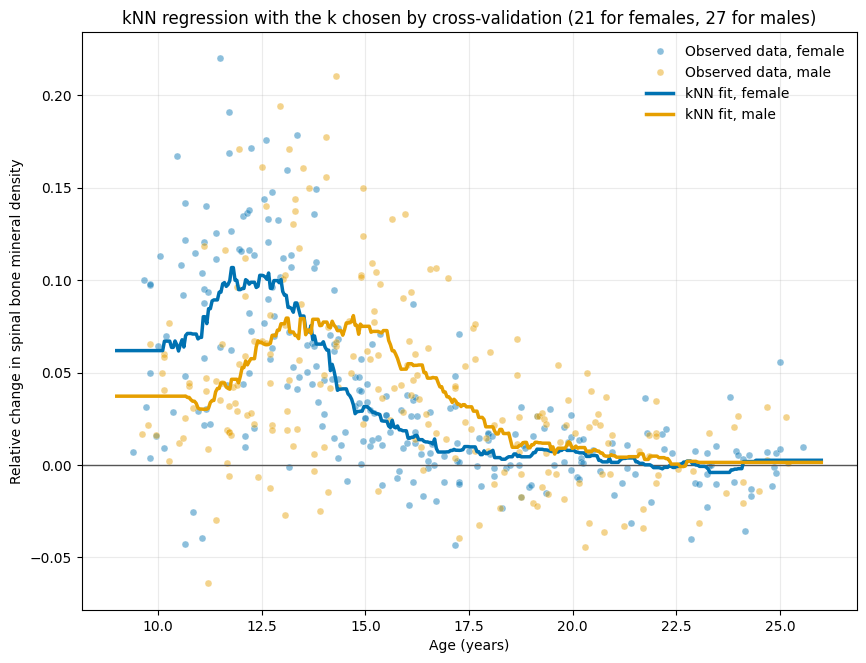

In [10]:
predict_2 = {}
for gender in genders:
    knn_2 = KNeighborsRegressor(n_neighbors=k_star[gender])
    knn_2.fit(x[gender], Y[gender])
    predict_2[gender] = knn_2.predict(x_grid)

fig, ax = plt.subplots(figsize=(10, 7.5))
plot_fit(ax, predict_2, f'kNN regression with the k chosen by cross-validation ({k_star["female"]} for females, {k_star["male"]} for males)')

The growth spurt of the females is about two years earlier than that of the males.

## The effect of k

Move the slider to change $k$ (this cell needs a running kernel).

In [11]:
def predict_k(k):
    return {gender: KNeighborsRegressor(n_neighbors=k).fit(x[gender], Y[gender]).predict(x_grid) for gender in genders}

def interactive_knn(k):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    plot_fit(ax, predict_k(k), f'kNN regression with k = {k}')
    plt.show()

interact(interactive_knn, k=IntSlider(value=10, min=1, max=150, description='k'));

interactive(children=(IntSlider(value=10, description='k', max=150, min=1), Output()), _dom_classes=('widget-i…

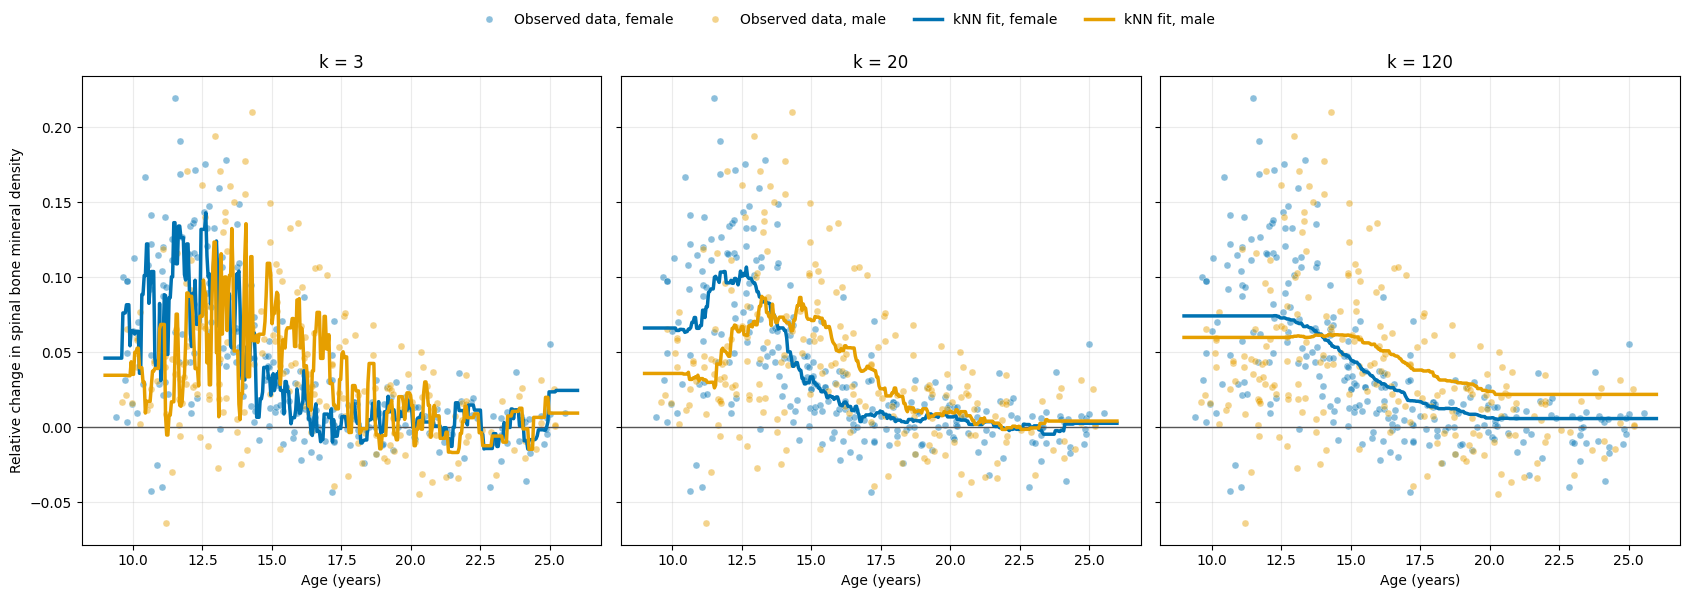

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6), sharey=True)
for ax, k in zip(axes, [3, 20, 120]):
    plot_fit(ax, predict_k(k), f'k = {k}', legend=False)
for ax in axes[1:]:
    ax.set_ylabel('')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))

## Smoothing with a kernel

The kNN fit is a step function: it jumps every time the set of neighbors changes. If instead of the plain average we use a weighted average, with weights that decrease with the distance, the fit is smoother.

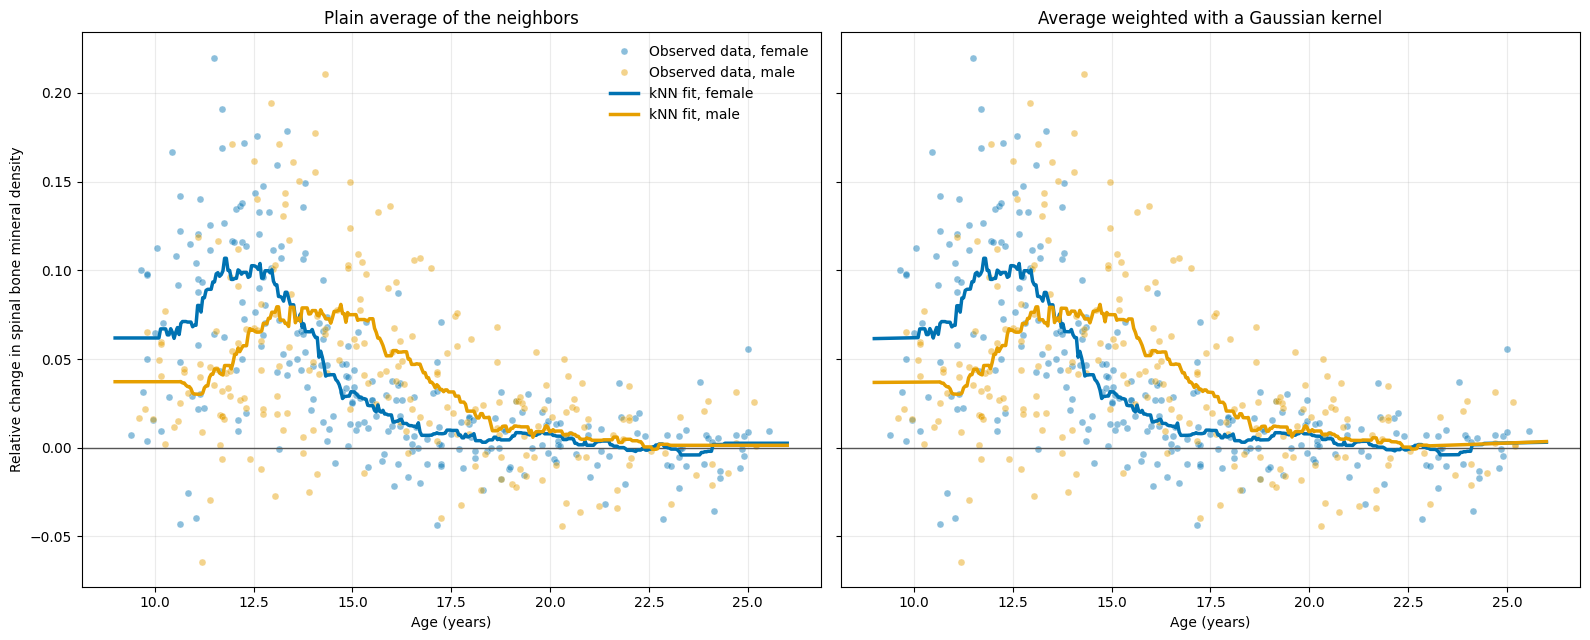

In [13]:
def gaussian_kernel(distances):
    h = 10
    weights = np.exp(-(distances**2)/h)
    return(weights)

predict_kernel = {}
for gender in genders:
    knn_kernel = KNeighborsRegressor(n_neighbors=k_star[gender], weights=gaussian_kernel)
    knn_kernel.fit(x[gender], Y[gender])
    predict_kernel[gender] = knn_kernel.predict(x_grid)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True)
plot_fit(axes[0], predict_2, 'Plain average of the neighbors')
plot_fit(axes[1], predict_kernel, 'Average weighted with a Gaussian kernel', legend=False)
axes[1].set_ylabel('')
plt.tight_layout()